# sklearn_code 算法参数与性能介绍

本 Notebook 系统整理 `sklearn_code` 框架内置的 **3 个回归算法**、**3 个分类算法** 与 **2 个特征工程算法**：

- 每个算法的用途、关键参数、默认值与调参要点；
- 在同一份 meteva 站点数据上的 **训练/预测耗时、模型体积、精度** 对比（回归：气温；分类：未来 1 小时是否降水、24 小时降水量级）；
- 关键参数（随机森林树数/深度、PCA 主成分数）对性能的影响。

## 算法清单

| 类型 | 算法名 | sklearn 类 | 参数入口 | 一句话说明 |
|---|---|---|---|---|
| 回归 | `linear` | `LinearRegression` | `model_kwargs` | 普通最小二乘线性回归，无正则 |
| 回归 | `random_forest` | `RandomForestRegressor` | `model_kwargs` | Bagging 决策树集成，非线性 |
| 回归 | `bayesian` | `BayesianRidge` | `model_kwargs` | 贝叶斯岭回归，自动正则 + 不确定性 |
| 分类 | `logistic` | `LogisticRegression` | `model_kwargs` | 线性分类器，可输出概率 |
| 分类 | `random_forest_classifier` | `RandomForestClassifier` | `model_kwargs` | Bagging 树分类集成，非线性 |
| 分类 | `svc` | `SVC` | `model_kwargs` | 支持向量分类，默认 RBF 核 |
| 特征工程 | `standard_scaler` | `StandardScaler` | `feat_kwargs` | 逐特征标准化（去均值、单位方差） |
| 特征工程 | `pca` | `PCA` | `feat_kwargs` | 主成分分析降维 |

> 算法名可传字符串（经 `AVAILABLE_MODELS` / `AVAILABLE_FEATURES` 映射），也可直接传 sklearn 类或实例；
> **回归还是分类由所选估计器自动判定**（`sklearn.base.is_classifier`），无需额外参数：
> 回归器输出连续值，分类器输出类别标签。特征工程与模型会自动组合为 sklearn `Pipeline`。
> 分类既支持二分类也支持多分类（如降水量级），预测列输出对应的类别标签。
> 完整参数表见 `docs/算法参数清单.md`。

**术语约定**：n = 样本数，p = 特征数，T = 树的数量，k = 主成分数。

## 一、环境准备

- 依赖见 `env/requirements.txt`（numpy / pandas / scikit-learn / joblib / matplotlib）。
- Notebook 位于 `nbs/`，代码会自动向上查找仓库根目录，不依赖启动位置。
- 计时为单次测量，受 CPU、并发与缓存影响，适合做量级比较，不宜当作精确基准。

In [1]:
%matplotlib inline
import io
import platform
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


def find_repo_root(start=None):
    """从当前工作目录向上查找仓库根目录（以 src/sklearn_plugin.py 为标志）。"""
    p = Path(start or Path.cwd()).resolve()
    for cand in (p, *p.parents):
        if (cand / "src" / "sklearn_plugin.py").is_file():
            return cand
    raise RuntimeError("未找到仓库根目录（缺少 src/sklearn_plugin.py）")


REPO_ROOT = find_repo_root()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.sklearn_plugin import (
    AVAILABLE_FEATURES,
    AVAILABLE_MODELS,
    SklearnCal,
)

import sklearn
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# 中文图表字体（Windows 常用字体，缺失时自动回退）
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

print("Python:", platform.python_version())
print("numpy:", np.__version__, "| pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__)
print("仓库根目录:", REPO_ROOT)
print("可用模型:", {k: v.__name__ for k, v in AVAILABLE_MODELS.items()})
print("可用特征工程:", {k: v.__name__ for k, v in AVAILABLE_FEATURES.items()})


Python: 3.11.9
numpy: 2.4.6 | pandas: 3.0.6 | scikit-learn: 1.9.1
仓库根目录: E:\sklearn_code
可用模型: {'linear': 'LinearRegression', 'random_forest': 'RandomForestRegressor', 'bayesian': 'BayesianRidge', 'logistic': 'LogisticRegression', 'random_forest_classifier': 'RandomForestClassifier', 'svc': 'SVC'}
可用特征工程: {'pca': 'PCA', 'standard_scaler': 'StandardScaler'}


## 二、数据与实验设置

- 数据文件：`resource/data/train_data.txt`（meteva 站点格式，前 6 列为 `level, time, dtime, id, lon, lat`）。
- 目标列：`TEM`（气温）。
- 特征列：风速/风向、降水与经纬度，共 11 个。
- 预处理：风向中的 `999017` 是业务缺测码，而框架只识别 `NaN` / `-9999.0`，因此先转成 `NaN`，再统一剔除缺测样本。

| 角色 | 列 |
|---|---|
| 目标 | `TEM` |
| 特征 | `WIN_S_Avg_10mi`, `WIN_D_Avg_10mi`, `WIN_S_inst_Max`, `WIN_D_INST_Max`, `PRE_1h`, `PRE_3h`, `PRE_6h`, `PRE_12h`, `PRE_24h`, `lon`, `lat` |
| 预处理 | 风向 `999017` → `NaN`；再剔除含 `NaN` / `-9999.0` 的样本 |

> 仓库 `cli/run.py` 的演示配置为 `FEATURE_COLS=["TEM", "PRE_1h", "PRE_3h", "PRE_6h"]`、`TARGET_COL="TEM"`，
> 即用 `TEM` 预测 `TEM`（恒等映射），无法区分算法优劣。本 Notebook 改用其他气象要素与经纬度作为特征，使对比有意义。
> `TEM_Max` / `TEM_Min` 与目标 `TEM` 的相关系数约 0.99，纳入后任务接近恒等映射，故未使用。

**划分方式**：80/20 随机划分（`random_state=42`）。同一站点/时次可能同时出现在训练集与测试集，指标会偏乐观；
正式预报评估应按时间切分。但所有算法共享同一划分，横向比较仍然公平。

数据中的 `PRE_1h`~`PRE_24h` 降水累计列既可作为特征，也可用于构造分类标签；第 4.2 节分别演示这两种用法。

In [2]:
DATA_PATH = REPO_ROOT / "resource" / "data" / "train_data.txt"
TARGET_COL = "TEM"
FEATURE_COLS = [
    "WIN_S_Avg_10mi", "WIN_D_Avg_10mi", "WIN_S_inst_Max", "WIN_D_INST_Max",
    "PRE_1h", "PRE_3h", "PRE_6h", "PRE_12h", "PRE_24h", "lon", "lat",
]

df = pd.read_csv(DATA_PATH)
# time 列混用 "YYYY-MM-DD HH:MM:SS" 与 "YYYY-MM-DD" 两种格式，
# pandas 严格解析下需显式 format="mixed"
df["time"] = pd.to_datetime(df["time"], format="mixed")
print(f"训练数据：{DATA_PATH}")
print(f"原始规模：{len(df):,} 行 × {df.shape[1]} 列")

# 风向里的 999017 是业务缺测码，框架只识别 NaN/-9999.0，这里先转换
for col in ["WIN_D_Avg_10mi", "WIN_D_INST_Max"]:
    n_bad = int((df[col] == 999017).sum())
    df.loc[df[col] == 999017, col] = np.nan
    print(f"{col}: 999017 缺测码 {n_bad} 个 → NaN")

X = np.asarray(df[FEATURE_COLS], dtype=np.float32)
y = np.asarray(df[TARGET_COL], dtype=np.float32)
valid = np.where(
    ~np.isnan(y)
    & (y != -9999.0)
    & ~np.any(np.isnan(X), axis=1)
    & ~np.any(X == -9999.0, axis=1)
)[0]
print(f"\n剔除缺测后：{len(valid):,} 行（剔除 {len(df) - len(valid):,} 行）")
print(f"有效样本：特征矩阵 {X[valid].shape}，目标 {y[valid].shape}")

X, y = X[valid], y[valid]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"训练集: {X_train.shape} | 测试集: {X_test.shape}")
print(
    f"目标 TEM: 均值 {y_train.mean():.3f}，标准差 {y_train.std():.3f}，"
    f"范围 [{y_train.min():.1f}, {y_train.max():.1f}]"
)

训练数据：E:\sklearn_code\resource\data\train_data.txt
原始规模：59,638 行 × 18 列
WIN_D_Avg_10mi: 999017 缺测码 1535 个 → NaN
WIN_D_INST_Max: 999017 缺测码 152 个 → NaN

剔除缺测后：56,559 行（剔除 3,079 行）
有效样本：特征矩阵 (56559, 11)，目标 (56559,)
训练集: (45247, 11) | 测试集: (11312, 11)
目标 TEM: 均值 26.263，标准差 4.471，范围 [2.1, 40.0]


## 三、算法参数速查

以下每张表列出**最常用、最影响性能**的参数；完整参数清单（含 sklearn 官方英文说明）见 `docs/算法参数清单.md`。

参数通过 `SklearnCal(model=..., model_kwargs={...}, feat_model=..., feat_kwargs={...})` 传入。


### 3.1 特征工程（`feat_kwargs`）

#### StandardScaler — 标准化

逐特征执行 `z = (x − μ) / σ`，不改变分布形状，只统一量纲。

| 参数 | 默认值 | 含义与调参要点 |
|---|---|---|
| `copy` | `True` | 为 `False` 时尽量原地缩放，可能覆盖输入数据 |
| `with_mean` | `True` | 是否去均值；稀疏矩阵必须设为 `False` |
| `with_std` | `True` | 是否缩放到单位方差 |

要点：

- 对**无正则的 LinearRegression**，标准化不改变理论最优解与点预测（只是系数缩放），实测指标应基本相同。
- 对 **BayesianRidge**，正则强度会按特征尺度自适应，点预测也基本不变；标准化主要改善数值条件与系数解释。
- 对**正则化线性模型、SVM/KNN、神经网络、PCA** 等尺度敏感算法，标准化通常是必需的。
- 特征工程与模型会被框架组合成 `Pipeline`，变换器只在训练集上 `fit`，避免信息泄漏。

#### PCA — 主成分分析

线性正交变换，按方差从大到小保留前 k 个主成分，用于降维、去共线、压缩与可视化。

| 参数 | 默认值 | 含义与调参要点 |
|---|---|---|
| `n_components` | `None` | 保留主成分数：`int` 为个数；`0<f<1` 为解释方差比例（需 `svd_solver='full'`）；`'mle'` 用 Minka MLE 估计；`None` 保留 `min(n_samples, n_features)` 个 |
| `whiten` | `False` | 白化：各主成分缩放到单位方差，可能提升下游模型，但会丢失部分信息 |
| `svd_solver` | `'auto'` | `auto` / `full`（精确 SVD）/ `covariance_eigh`（n≫p 高效）/ `arpack`（截断 SVD）/ `randomized`（随机 SVD） |
| `tol` | `0.0` | `arpack` 求解器的奇异值容差 |
| `iterated_power` | `'auto'` | `randomized` 求解器的幂迭代次数 |
| `random_state` | `None` | `arpack` / `randomized` 下控制可复现性 |

要点：

- PCA 是**无监督**的：保留方差大的方向，不等于保留与预测目标相关的方向（见第五节实验）。
- PCA 对特征尺度敏感；未标准化时，量纲大的特征会主导主成分。使用前通常应先标准化。
- 框架每个 `feat_model` 只接受一个变换器；若要“标准化 + PCA”，可传入 sklearn `Pipeline` 实例作为 `feat_model`（实例方式不能再传 `feat_kwargs`）：

  ```python
  feat = Pipeline([("scaler", StandardScaler()), ("pca", PCA(n_components=4))])
  ```

### 3.2 回归模型（`model_kwargs`）

#### LinearRegression — 普通最小二乘

拟合 `y = Xw + b`，最小化残差平方和；无正则项。

| 参数 | 默认值 | 含义与调参要点 |
|---|---|---|
| `fit_intercept` | `True` | 是否拟合截距；数据未中心化时保持 `True` |
| `copy_X` | `True` | 为 `False` 时可能覆盖输入矩阵 |
| `n_jobs` | `None` | 并行计算；仅在多目标、稀疏矩阵或 `positive=True` 时有加速；`None`=1，`-1`=全部核 |
| `positive` | `False` | 强制系数非负（仅稠密数组） |

要点：

- 对特征尺度不敏感（无正则项）；存在强共线性时系数不稳定，但点预测通常仍稳定。
- 训练复杂度约 `O(np² + p³)`，预测 `O(p)`；模型仅保存 `p+1` 个参数，体积极小。
- 作为基线模型：先看线性模型的残差是否还有结构，再决定是否上非线性模型。

#### BayesianRidge — 贝叶斯岭回归

对权重施加 Gaussian 先验，用证据最大化自动估计噪声精度 `alpha` 与权重精度 `lambda`，等价于自适应岭回归。

| 参数 | 默认值 | 含义与调参要点 |
|---|---|---|
| `max_iter` | `300` | 最大迭代次数 |
| `tol` | `1e-3` | 收敛阈值 |
| `alpha_1` / `alpha_2` | `1e-6` | 噪声精度 `alpha` 的 Gamma 先验形状 / 率参数 |
| `lambda_1` / `lambda_2` | `1e-6` | 权重精度 `lambda` 的 Gamma 先验形状 / 率参数 |
| `alpha_init` / `lambda_init` | `None` | 初值；默认 `alpha_init=1/Var(y)`、`lambda_init=1` |
| `compute_score` | `False` | 每轮计算对数边际似然，便于调试收敛 |
| `fit_intercept` | `True` | 是否拟合截距 |
| `copy_X` | `True` | 为 `False` 时可能覆盖输入矩阵 |
| `verbose` | `False` | 输出迭代信息 |

要点：

- `predict(X, return_std=True)` 可返回预测标准差，用于不确定性/区间估计；拟合后可用 `alpha_`、`lambda_` 查看自动估计值。
- 点预测对特征尺度基本不敏感（正则强度会随尺度调整），但标准化仍有助于数值稳定与系数解释。
- 每轮迭代约 `O(np² + p³)`，最多 `max_iter` 轮；模型体积 `O(p)`。
- 先验超参默认 `1e-6` 属于弱信息先验，通常无需调整；收敛困难时可设置 `alpha_init` 或增大 `max_iter`。

#### RandomForestRegressor — 随机森林回归

Bagging 集成多棵 CART 回归树，每次分裂随机选取特征子集；无需标准化，能捕捉非线性与交互。

| 参数 | 默认值 | 含义与调参要点 |
|---|---|---|
| `n_estimators` | `100` | 树的数量；增加通常提升精度但边际递减，训练时间/体积近似线性增长 |
| `criterion` | `'squared_error'` | 分裂准则：`squared_error`（MSE）/ `absolute_error`（MAE，较慢）/ `friedman_mse` / `poisson` |
| `max_depth` | `None` | 最大深度；`None` 完全生长，精度高但易过拟合、模型体积大 |
| `min_samples_split` | `2` | 内部节点再分裂所需最小样本数（int 或比例） |
| `min_samples_leaf` | `1` | 叶节点最小样本数；增大可平滑模型、抑制过拟合、减小体积 |
| `max_features` | `1.0` | 每次分裂考虑的特征数；`1.0`=全部（bagging），`'sqrt'`/`'log2'`/比例可增加随机性 |
| `max_leaf_nodes` | `None` | 最大叶节点数（best-first 生长）；`None` 不限制 |
| `min_impurity_decrease` | `0.0` | 分裂带来的最小不纯度下降 |
| `bootstrap` | `True` | 是否有放回抽样构建每棵树 |
| `oob_score` | `False` | 用袋外样本估计泛化精度（需 `bootstrap=True`） |
| `n_jobs` | `None` | 树级并行；`None`=1，`-1`=全部核（内存占用随之上升） |
| `random_state` | `None` | 控制自助采样与特征抽样，固定后可复现 |
| `ccp_alpha` | `0.0` | 最小代价复杂度剪枝参数；增大可剪枝、减小体积 |
| `max_samples` | `None` | 每棵树的抽样数量（`bootstrap=True` 时生效） |
| `monotonic_cst` | `None` | 逐特征单调性约束（1/0/-1）；不支持多输出或缺失值 |
| `warm_start` | `False` | 复用上次模型继续加树 |
| `verbose` | `0` | 拟合/预测详细程度 |

要点：

- 单树训练近似 `O(n log n · max_features)`，预测 `O(depth)`；整体训练 `O(T · n log n · max_features)`，预测 `O(T · depth)`。
- 模型体积与 `树数 × 节点数` 成正比；本数据上默认 `n_estimators=100, max_depth=None` 的模型约 365 MB，**生产环境务必限制深度/叶节点**。
- 常用折中：`n_estimators=100~300`、`max_depth=8~12`、`min_samples_leaf=1~5`、`max_features='sqrt'` 或 `0.3~0.5`。
- 特征尺度不影响树分裂，因此**不需要标准化**；这也是 RF 流程简单的原因之一。

### 3.3 分类模型（`model_kwargs`）

> **多分类**：三种分类器都支持多类别标签（如降水量级）。`LogisticRegression` 默认按多分类（multinomial）处理，`SVC` 使用一对一（OvO）策略，`RandomForestClassifier` 原生多分类；评估多分类时应看 macro/weighted 平均的 Precision/Recall/F1 与混淆矩阵。

#### LogisticRegression — 逻辑回归

线性分类器，用 sigmoid/softmax 将线性得分映射为类别概率；`C` 为正则强度倒数（越小正则越强）。

| 参数 | 默认值 | 含义与调参要点 |
|---|---|---|
| `C` | `1.0` | 正则强度倒数；越小正则越强、越不易过拟合 |
| `penalty` | `'l2'` | 正则类型：`l1` / `l2` / `elasticnet` / `None` |
| `solver` | `'lbfgs'` | 优化器；`l1`/`elasticnet` 需 `saga` 或 `liblinear` |
| `max_iter` | `100` | 最大迭代次数；不收敛时调大（如 1000~2000） |
| `class_weight` | `None` | `'balanced'` 按类别频率反比加权，缓解不平衡 |
| `fit_intercept` | `True` | 是否拟合截距 |
| `l1_ratio` | `None` | Elastic-Net 混合系数，仅 `penalty='elasticnet'` 时使用 |
| `n_jobs` | `None` | 多分类 OvR 时的并行核数 |

要点：

- 对特征尺度敏感，建议搭配 `standard_scaler`；训练/预测极快，适合做分类基线。
- 不平衡数据用 `class_weight='balanced'`，评估看少数类 Precision/Recall/F1，而非 Accuracy。
- `predict_proba` 可输出类别概率；本框架当前只输出预测标签。

#### RandomForestClassifier — 随机森林分类

Bagging 集成多棵 CART 分类树，无需标准化；参数与回归版基本一致，区别在分裂准则与 `class_weight`。

| 参数 | 默认值 | 含义与调参要点 |
|---|---|---|
| `n_estimators` | `100` | 树的数量；精度提升边际递减，耗时/体积近似线性增长 |
| `criterion` | `'gini'` | 分裂准则：`gini` / `entropy` / `log_loss` |
| `max_depth` | `None` | 最大深度；`None` 完全生长，易过拟合且体积大 |
| `min_samples_split` | `2` | 内部节点再分裂所需最小样本数 |
| `min_samples_leaf` | `1` | 叶节点最小样本数；增大可平滑模型 |
| `max_features` | `'sqrt'` | 每次分裂考虑的特征数；分类默认 `sqrt(p)` |
| `class_weight` | `None` | `'balanced'` 或 `'balanced_subsample'` 缓解不平衡 |
| `n_jobs` | `None` | 树级并行；`None`=1，`-1`=全部核 |
| `random_state` | `None` | 控制自助采样与特征抽样，固定后可复现 |
| `ccp_alpha` | `0.0` | 最小代价复杂度剪枝参数 |
| `max_samples` | `None` | 每棵树的抽样数量（`bootstrap=True` 时生效） |

要点：

- 非线性与交互建模能力强，对特征尺度不敏感；精度/体积权衡同样靠 `max_depth`、`min_samples_leaf`、`n_estimators`。
- 不平衡数据可用 `class_weight='balanced'`；`oob_score=True` 可做袋外评估。

#### SVC — 支持向量分类

最大化分类间隔；默认 RBF 核，`C` 与 `gamma` 是核心超参。

| 参数 | 默认值 | 含义与调参要点 |
|---|---|---|
| `C` | `1.0` | 正则参数；越大越拟合训练集、越易过拟合 |
| `kernel` | `'rbf'` | 核函数：`linear` / `poly` / `rbf` / `sigmoid` / 自定义 |
| `gamma` | `'scale'` | RBF/poly/sigmoid 核系数；越大决策边界越复杂 |
| `degree` | `3` | 多项式核次数（仅 `poly`） |
| `coef0` | `0.0` | 核函数常数项（仅 `poly` / `sigmoid`） |
| `probability` | `False` | 是否启用概率估计；开启会变慢且与 `predict` 不完全一致 |
| `class_weight` | `None` | `'balanced'` 按类别频率反比加权 |
| `tol` | `1e-3` | 停止容差 |
| `max_iter` | `-1` | 迭代上限，`-1` 不限制 |
| `cache_size` | `200` | 核缓存大小（MB） |
| `decision_function_shape` | `'ovr'` | 多分类决策函数形状：`ovo` / `ovr` |
| `random_state` | `None` | 概率估计打乱数据时控制随机性 |

要点：

- 对特征尺度敏感，建议搭配 `standard_scaler`；中小样本、高维场景表现好。
- 训练复杂度接近 `O(n²)`~`O(n³)`，样本量大（>1 万）时耗时/内存显著增加，必要时抽样、改用线性核或换随机森林。
- 默认 `probability=False` 时只能 `predict` 标签、不能 `predict_proba`；本框架输出标签，无需开启。

### 3.4 参数对性能的影响速查

| 参数变化 | 精度/效果 | 训练耗时 | 模型体积 | 预测耗时 |
|---|---|---|---|---|
| RF `n_estimators` ↑ | 方差下降，精度上升后饱和 | 近似线性 ↑ | 近似线性 ↑ | ↑ |
| RF `max_depth` ↑ | 偏差下降，可能过拟合 | ↑ | 快速 ↑（近似指数） | ↑ |
| RF `min_samples_leaf` ↑ | 平滑、方差下降，可能欠拟合 | 略 ↑ | ↓ | ↓ |
| RF `max_features` ↓ | 单树更弱、随机性更强，需更多树 | ↓ | — | — |
| RF `ccp_alpha` ↑ | 剪枝增强，可能欠拟合 | 略 ↑ | ↓ | ↓ |
| PCA `n_components` ↑ | 保留信息更多，降维收益减少 | ↑ | ↑ | ↑ |
| PCA `whiten=True` | 各主成分等方差，可能利于下游 | — | — | — |
| StandardScaler | 对无正则线性/贝叶斯点预测不变 | 略 ↑ | 略 ↑ | 略 ↑ |
| BayesianRidge `max_iter` ↑ | 更充分收敛 | ↑ | — | — |
| 逻辑回归 / SVC `C` ↑ | 正则减弱，训练集拟合更强、可能过拟合 | ↑ | — | — |
| SVC `gamma` ↑ | 决策边界更复杂，可能过拟合 | ↑ | ↑（支持向量变多） | ↑ |
| `class_weight='balanced'` | 提升少数类召回，整体 Accuracy 可能下降 | — | — | — |
| 分类 RF `max_depth` ↑ | 同回归：精度先升后可能过拟合 | ↑ | 快速 ↑ | ↑ |
| `n_jobs=-1` | 不变 | ↓（多核） | — | — |

> 表中“↑/↓”为一般趋势，实际幅度取决于数据规模、特征相关性与硬件。

## 四、性能基准：精度 / 耗时 / 体积

本节分别给出回归（4.1）与分类（4.2）的精度、耗时与模型体积基准。

### 4.1 回归：气温

**实验协议**

- 数据：`resource/data/train_data.txt`，目标 `TEM`，11 个特征；缺测剔除后 80/20 随机划分（`random_state=42`）。
- 指标：测试集 `RMSE`、`MAE`、`R²`；`fit`/`predict` 用时用 `time.perf_counter()` 单次测量；模型体积用 `joblib` 序列化到内存后的字节数。
- 随机森林固定 `random_state=42`、`n_jobs=-1`；其余算法使用 sklearn 默认参数。
- 基准部分按 `AVAILABLE_MODELS` / `AVAILABLE_FEATURES` 映射构建估计器（等价于插件内部构建逻辑），以排除数据清洗等框架开销对计时的影响；第七节再演示 `SklearnCal.process` 的完整用法。
- 计时受 CPU、并发与缓存影响，仅用于量级比较；请在自己的环境复跑。

| 配置 | 模型 | 特征工程 | 观察点 |
|---|---|---|---|
| `linear` | LinearRegression | 无 | 线性基线、极限速度 |
| `bayesian` | BayesianRidge | 无 | 自动正则、可输出不确定性 |
| `random_forest` | RandomForestRegressor（100 树，不限深度） | 无 | 非线性精度上限、体积代价 |
| `linear + standard_scaler` | LinearRegression | StandardScaler | 标准化对无正则模型的影响 |
| `bayesian + standard_scaler` | BayesianRidge | StandardScaler | 标准化对自适应正则的影响 |
| `linear + pca(4)` | LinearRegression | PCA(4) | 无监督降维对精度的影响 |
| `linear + scaler → pca(4)` | LinearRegression | StandardScaler → PCA(4) | 标准化后再降维 |


In [3]:
def make_estimator(model, model_kwargs=None, feat_model=None, feat_kwargs=None):
    """按框架映射表构建估计器；feat_model 可为字符串或变换器实例。"""
    model_kwargs = dict(model_kwargs or {})
    feat_kwargs = dict(feat_kwargs or {})
    estimator = AVAILABLE_MODELS[model](**model_kwargs)
    if feat_model is not None:
        transformer = (
            AVAILABLE_FEATURES[feat_model](**feat_kwargs)
            if isinstance(feat_model, str)
            else feat_model
        )
        estimator = Pipeline(
            [("feature_engineering", transformer), ("model", estimator)]
        )
    return estimator


def model_size_mb(estimator):
    """用 joblib 序列化后的字节数衡量模型体积。"""
    buffer = io.BytesIO()
    joblib.dump(estimator, buffer)
    size_mb = buffer.tell() / 1024 ** 2
    buffer.close()
    return size_mb


def benchmark(label, model, model_kwargs=None, feat_model=None, feat_kwargs=None):
    estimator = make_estimator(model, model_kwargs, feat_model, feat_kwargs)

    t0 = time.perf_counter()
    estimator.fit(X_train, y_train)
    fit_s = time.perf_counter() - t0

    t0 = time.perf_counter()
    y_pred = estimator.predict(X_test)
    predict_ms = (time.perf_counter() - t0) * 1000

    rmse = float(np.sqrt(mean_squared_error(y_test, y_pred)))
    return {
        "配置": label,
        "算法": model,
        "特征工程": (
            feat_model
            if isinstance(feat_model, str)
            else ("scaler+pca" if feat_model is not None else "—")
        ),
        "训练耗时(s)": fit_s,
        "预测耗时(ms)": predict_ms,
        "模型体积(MB)": model_size_mb(estimator),
        "RMSE": rmse,
        "MAE": float(mean_absolute_error(y_test, y_pred)),
        "R²": float(r2_score(y_test, y_pred)),
        "y_pred": y_pred,
    }


SCALER_PCA = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=4, random_state=42)),
])

BENCHMARK_CONFIGS = [
    ("linear", "linear", {}, None, {}),
    ("bayesian", "bayesian", {}, None, {}),
    ("random_forest", "random_forest",
     {"n_estimators": 100, "n_jobs": -1, "random_state": 42}, None, {}),
    ("linear + standard_scaler", "linear", {}, "standard_scaler", {}),
    ("bayesian + standard_scaler", "bayesian", {}, "standard_scaler", {}),
    ("linear + pca(4)（原始特征）", "linear", {}, "pca",
     {"n_components": 4, "random_state": 42}),
    ("linear + scaler → pca(4)", "linear", {}, SCALER_PCA, {}),
]

records = []
predictions = {}
for label, model, mkw, feat, fkw in BENCHMARK_CONFIGS:
    record = benchmark(label, model, mkw, feat, fkw)
    predictions[label] = record.pop("y_pred")
    records.append(record)
    print(f"[完成] {label}")

results = pd.DataFrame(records)
display(results.round(4))

[完成] linear
[完成] bayesian


[完成] random_forest
[完成] linear + standard_scaler
[完成] bayesian + standard_scaler
[完成] linear + pca(4)（原始特征）
[完成] linear + scaler → pca(4)


,配置,算法,特征工程,训练耗时(s),预测耗时(ms),模型体积(MB),RMSE,MAE,R²
0,linear,linear,—,0.0223,1.4979,0.0006,4.0799,2.9664,0.1816
1,bayesian,bayesian,—,0.0231,0.6210,0.0014,4.0797,2.9661,0.1817
2,random_forest,random_forest,—,8.4638,181.8605,364.8120,1.9709,1.4282,0.8090
3,linear + standard_scaler,linear,standard_scaler,0.0394,2.4164,0.0013,4.0799,2.9664,0.1816
4,bayesian + standard_scaler,bayesian,standard_scaler,0.0346,1.3805,0.0021,4.0798,2.9663,0.1816
5,linear + pca(4)（原始特征）,linear,pca,0.0156,1.3388,0.0016,4.2141,3.1206,0.1269
6,linear + scaler → pca(4),linear,scaler+pca,0.0318,3.4722,0.0022,4.2725,3.1229,0.1025


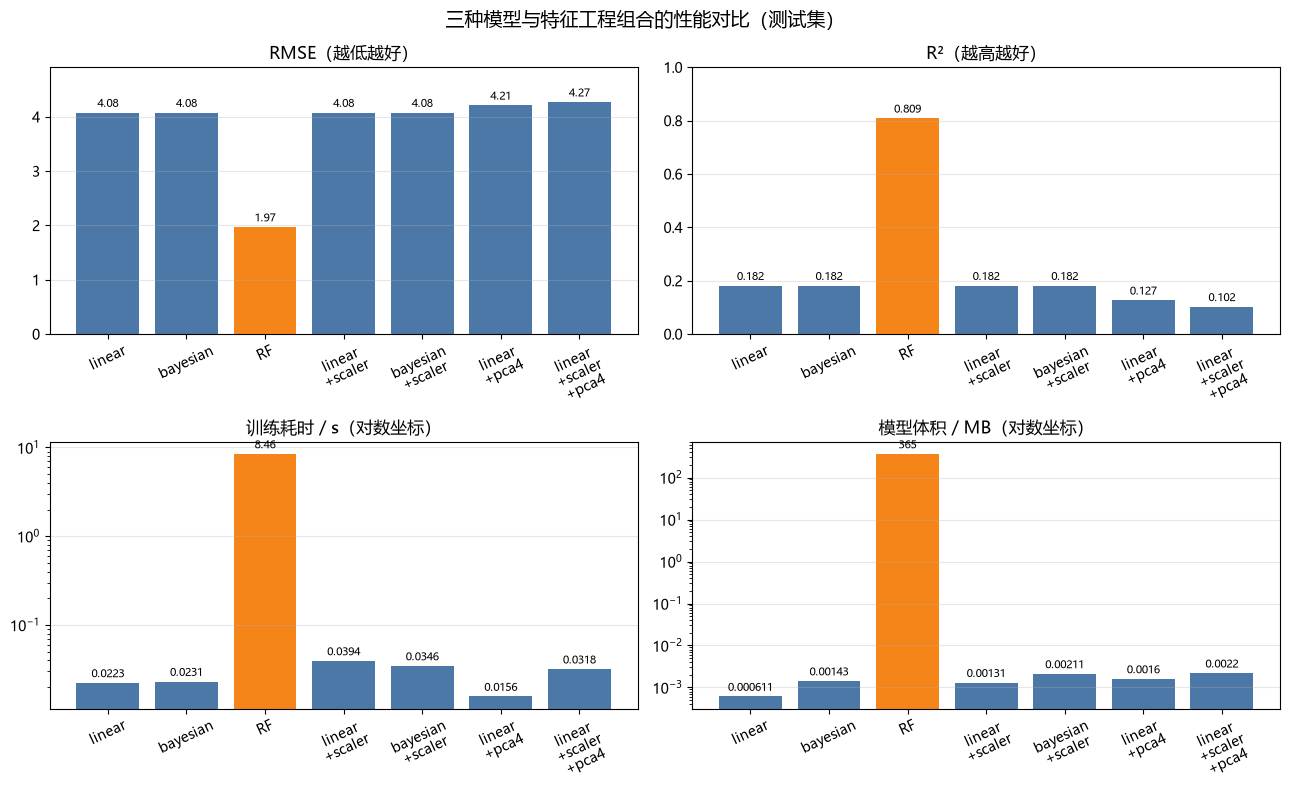

In [4]:
short_labels = [
    "linear", "bayesian", "RF", "linear\n+scaler",
    "bayesian\n+scaler", "linear\n+pca4", "linear\n+scaler\n+pca4",
]
colors = ["#4C78A8"] * len(results)
colors[2] = "#F58518"  # 突出随机森林

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
panels = [
    ("RMSE", "RMSE（越低越好）", False),
    ("R²", "R²（越高越好）", False),
    ("训练耗时(s)", "训练耗时 / s（对数坐标）", True),
    ("模型体积(MB)", "模型体积 / MB（对数坐标）", True),
]
for ax, (col, title, logy) in zip(axes.ravel(), panels):
    bars = ax.bar(short_labels, results[col], color=colors)
    if logy:
        ax.set_yscale("log")
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.3)
    ax.bar_label(bars, fmt="%.3g", padding=2, fontsize=8)

axes[0, 0].set_ylim(0, results["RMSE"].max() * 1.15)
axes[0, 1].set_ylim(0, 1.0)
plt.suptitle("三种模型与特征工程组合的性能对比（测试集）", fontsize=14)
plt.tight_layout()
plt.show()

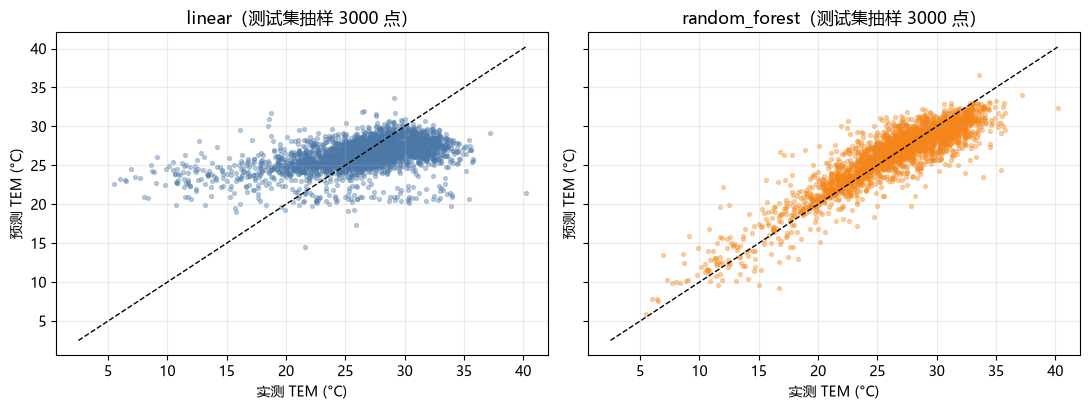

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)
for ax, label, color in zip(
    axes, ["linear", "random_forest"], ["#4C78A8", "#F58518"]
):
    idx = np.random.RandomState(0).choice(
        len(y_test), size=min(3000, len(y_test)), replace=False
    )
    ax.scatter(y_test[idx], predictions[label][idx], s=8, alpha=0.35, color=color)
    lims = [y_test.min(), y_test.max()]
    ax.plot(lims, lims, "k--", lw=1)
    ax.set_title(f"{label}（测试集抽样 3000 点）")
    ax.set_xlabel("实测 TEM (°C)")
    ax.set_ylabel("预测 TEM (°C)")
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**4.1 结果解读**

- 线性/贝叶斯：`R² ≈ 0.18`，训练约 10 ms，模型 <2 KB；两者点预测几乎相同（BayesianRidge 的正则强度随尺度自适应），但贝叶斯额外提供 `return_std` 不确定性。
- 随机森林：`R² ≈ 0.81`，明显更好；代价是训练约 7 s、预测约 0.25 s / 1.1 万行、默认模型约 365 MB（100 棵不限深度）。
- StandardScaler 对 `LinearRegression` / `BayesianRidge` 的点预测无影响（R²/RMSE 相同），仅增加少量推理开销和体积；其价值体现在正则化、距离类、神经网络与 PCA 等对尺度敏感的算法。
- PCA(4) 将 R² 从约 0.18 降到约 0.10–0.13：无监督降维保留的是**方差大**的方向，不等于**与目标相关**的方向；11 维压缩到 4 维损失了预测信息。先标准化再 PCA 也不能挽回。
- 随机森林的精度优势来自非线性/交互，散点图中预测点更贴近 45° 参考线。
- 随机划分说明：同一站点/时次可能同时出现在训练与测试集，指标偏乐观；但所有算法共享同一划分，横向比较仍公平。

### 4.2 分类：降水

分类与回归共用同一套 `SklearnCal` 接口，任务类型由估计器自动判定。数据中的降水累计列（`PRE_1h` ~ `PRE_24h`）在下面两个任务中分别作为**特征**和**标签**：

| 任务 | 标签 | 降水列的用法 | 类别数 |
|---|---|---|---|
| 4.2.1 未来 1 小时是否降水 | `PRE_1h` 在 `t+1` 时刻是否 > 0 | 当前时刻各累计列全部作为特征 | 2 |
| 4.2.2 24 小时降水量级 | `PRE_24h` 按雨量分级 | 作为标签来源，不作为特征（避免嵌套泄漏） | 5 |

#### 4.2.1 二分类：未来 1 小时是否降水

- **标签构造**：同一站点**下一小时**的 `PRE_1h > 0`，按 `id` 排序后用 `groupby("id")["PRE_1h"].shift(-1)` 得到；只保留相邻 1 小时的样本，避免把跨缺测时段的两条记录配成相邻时刻。
- **特征**：当前时刻的 `TEM`、`TEM_Max`、`TEM_Min`、风速风向（缺测码 `999017` → `NaN`）、经纬度，以及当前 `PRE_1h` / `PRE_3h` / `PRE_6h` / `PRE_12h` / `PRE_24h` 降水累计列。
- **无泄漏**：特征是 `t` 时刻及以前的信息，标签是 `t+1` 时刻的降水，属于短时临近预报设定。
- **划分**：按标签分层抽样 80/20（`stratify=rain_next`）。
- **指标**：Accuracy / Precision / Recall / F1。正类约 9.8%，类别不平衡，应重点看少数类 Recall 与 F1，而非 Accuracy。
- **不平衡处理**：`class_weight="balanced"`。
- **速度**：RBF 核 `SVC` 训练复杂度接近 `O(n²)`，本节在训练集上抽样 6000 条控制耗时，其余模型使用全量训练集。

In [6]:
# ---- 4.2.1 二分类：未来 1 小时是否降水（标签取 t+1 时刻，特征只用 t 及以前）----
clf_df = df.sort_values(["id", "time"]).reset_index(drop=True)

next_pre = clf_df.groupby("id")["PRE_1h"].shift(-1)
next_time = clf_df.groupby("id")["time"].shift(-1)
# 只保留相邻 1 小时的两条记录，避免跨缺测时段错误配对
adjacent = (next_time - clf_df["time"]) == pd.Timedelta(hours=1)
clf_df["rain_next"] = np.where(
    adjacent & next_pre.notna(), (next_pre > 0).astype(float), np.nan
)

CLF_FEATURES = [
    "TEM", "TEM_Max", "TEM_Min",
    "WIN_S_Avg_10mi", "WIN_D_Avg_10mi",
    "WIN_S_inst_Max", "WIN_D_INST_Max",
    "PRE_1h", "PRE_3h", "PRE_6h", "PRE_12h", "PRE_24h",
    "lon", "lat",
]

# 标签或任一特征缺测（NaN / -9999.0）的行剔除
clf_mask = (
    clf_df["rain_next"].notna()
    & clf_df[CLF_FEATURES].notna().all(axis=1)
    & (clf_df[CLF_FEATURES] != -9999.0).all(axis=1)
)
clf_df = clf_df.loc[clf_mask].reset_index(drop=True)

train_idx, test_idx = train_test_split(
    np.arange(len(clf_df)), test_size=0.2, random_state=42,
    stratify=clf_df["rain_next"],
)
clf_train = clf_df.iloc[train_idx].reset_index(drop=True)
clf_test = clf_df.iloc[test_idx].reset_index(drop=True)

print(f"二分类样本：{len(clf_df):,} 行")
print(f"正类（未来 1 小时有降水）占比：{clf_df['rain_next'].mean():.2%}")
print(f"训练集：{len(clf_train):,} 行 | 测试集：{len(clf_test):,} 行")

# ---- 4.2.2 多分类：24 小时降水量级（标签来自 PRE_24h）----
GRADE_BINS = [-0.001, 0.1, 10, 25, 50, np.inf]
GRADE_LABELS = ["无降水", "小雨", "中雨", "大雨", "暴雨"]

grade_df = df.sort_values(["id", "time"]).reset_index(drop=True).copy()
grade_df["rain_grade"] = pd.cut(
    grade_df["PRE_24h"], bins=GRADE_BINS,
    labels=GRADE_LABELS, right=False,
)

# 不使用任何降水累计列：PRE_24h 是标签来源，其余窗口与它嵌套（PRE_24h ≥ PRE_12h …）
GRADE_FEATURES = [
    "TEM", "TEM_Max", "TEM_Min",
    "WIN_S_Avg_10mi", "WIN_D_Avg_10mi",
    "WIN_S_inst_Max", "WIN_D_INST_Max",
    "lon", "lat",
]

grade_mask = (
    grade_df["rain_grade"].notna()
    & grade_df[GRADE_FEATURES].notna().all(axis=1)
    & (grade_df[GRADE_FEATURES] != -9999.0).all(axis=1)
)
grade_df = grade_df.loc[grade_mask].reset_index(drop=True)

g_train_idx, g_test_idx = train_test_split(
    np.arange(len(grade_df)), test_size=0.2, random_state=42,
    stratify=grade_df["rain_grade"],
)
grade_train = grade_df.iloc[g_train_idx].reset_index(drop=True)
grade_test = grade_df.iloc[g_test_idx].reset_index(drop=True)

print()
print(f"多分类样本：{len(grade_df):,} 行")
print("训练集等级占比：")
print(grade_train["rain_grade"].value_counts(normalize=True).round(4).to_string())

二分类样本：54,140 行
正类（未来 1 小时有降水）占比：9.80%
训练集：43,312 行 | 测试集：10,828 行

多分类样本：56,619 行
训练集等级占比：
rain_grade
无降水    0.4753
小雨     0.3437
中雨     0.0968
大雨     0.0558
暴雨     0.0284


In [7]:
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
)

SVC_TRAIN_SIZE = 6000
clf_configs = [
    (
        "logistic（全量训练集）",
        SklearnCal(
            model="logistic",
            model_kwargs={"max_iter": 2000, "class_weight": "balanced"},
            feat_model="standard_scaler",
        ),
        clf_train,
    ),
    (
        "random_forest_classifier（全量训练集）",
        SklearnCal(
            model="random_forest_classifier",
            model_kwargs={
                "n_estimators": 100, "max_depth": 10,
                "class_weight": "balanced",
                "n_jobs": -1, "random_state": 42,
            },
        ),
        clf_train,
    ),
    (
        f"svc（训练集抽样 {SVC_TRAIN_SIZE}）",
        SklearnCal(
            model="svc",
            model_kwargs={
                "kernel": "rbf", "C": 1.0, "gamma": "scale",
                "class_weight": "balanced", "random_state": 42,
            },
            feat_model="standard_scaler",
        ),
        clf_train.sample(n=SVC_TRAIN_SIZE, random_state=42),
    ),
]

records = []
for label, cal, train_part in clf_configs:
    t0 = time.perf_counter()
    cal.process(
        train_part, feature_cols=CLF_FEATURES,
        target_col="rain_next", mode="train",
    )
    fit_s = time.perf_counter() - t0

    t0 = time.perf_counter()
    pred_df = cal.process(
        clf_test, feature_cols=CLF_FEATURES,
        mode="predict", data_name="rain_next_pred",
    )
    predict_ms = (time.perf_counter() - t0) * 1000

    y_true = clf_test["rain_next"].to_numpy()
    y_pred = pred_df["rain_next_pred"].to_numpy()
    records.append({
        "模型": label,
        "训练耗时(s)": fit_s,
        "预测耗时(ms)": predict_ms,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
    })
    print(f"[完成] {label}")

clf_results = pd.DataFrame(records)
display(clf_results.round(4))

[完成] logistic（全量训练集）


[完成] random_forest_classifier（全量训练集）


[完成] svc（训练集抽样 6000）


,模型,训练耗时(s),预测耗时(ms),Accuracy,Precision,Recall,F1
0,logistic（全量训练集）,0.1909,118.0306,0.8387,0.3360,0.6626,0.4459
1,random_forest_classifier（全量训练集）,1.6592,75.4457,0.8825,0.4387,0.7116,0.5428
2,svc（训练集抽样 6000）,1.6256,4385.2160,0.8610,0.3758,0.6334,0.4717


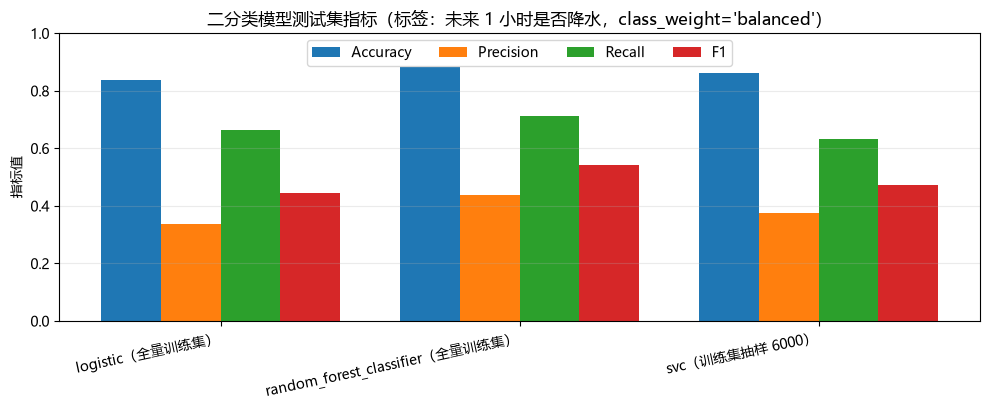

In [8]:
metrics = ["Accuracy", "Precision", "Recall", "F1"]
x = np.arange(len(clf_results))
width = 0.8 / len(metrics)

fig, ax = plt.subplots(figsize=(10, 4.2))
for i, name in enumerate(metrics):
    ax.bar(
        x + (i - (len(metrics) - 1) / 2) * width,
        clf_results[name], width=width, label=name,
    )
ax.set_xticks(x)
ax.set_xticklabels(clf_results["模型"], rotation=12, ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("指标值")
ax.set_title("二分类模型测试集指标（标签：未来 1 小时是否降水，class_weight='balanced'）")
ax.legend(ncol=4, loc="upper center")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

#### 4.2.2 多分类：24 小时降水量级

- **标签构造**：按业务常用量级把 `PRE_24h` 划为 5 级（mm）：`无降水 < 0.1`、`小雨 0.1–9.9`、`中雨 10–24.9`、`大雨 25–49.9`、`暴雨 ≥ 50`；训练集占比约 47.5% / 34.4% / 9.7% / 5.6% / 2.8%。
- **特征**：气温、风速风向与经纬度。**不使用任何降水累计列**——`PRE_24h` 是标签来源，`PRE_12h` 等窗口与它存在嵌套关系（`PRE_24h ≥ PRE_12h`），用作特征会直接泄漏标签。
- **划分**：按等级分层抽样 80/20（`stratify=rain_grade`）。
- **指标**：多分类看 Accuracy 与 **macro 平均**的 Precision / Recall / F1（各类等权，更关注大雨/暴雨等小类）；单看 Accuracy 会被“无降水”多数类主导。
- **模型**：三种分类器都原生支持多分类（SVC 采用一对一策略）；SVC 仍在训练集抽样 6000 条控制耗时。

In [9]:
grade_configs = [
    (
        "logistic（全量训练集）",
        SklearnCal(
            model="logistic",
            model_kwargs={"max_iter": 2000, "class_weight": "balanced"},
            feat_model="standard_scaler",
        ),
        grade_train,
    ),
    (
        "random_forest_classifier（全量训练集）",
        SklearnCal(
            model="random_forest_classifier",
            model_kwargs={
                "n_estimators": 100, "max_depth": 10,
                "class_weight": "balanced",
                "n_jobs": -1, "random_state": 42,
            },
        ),
        grade_train,
    ),
    (
        f"svc（训练集抽样 {SVC_TRAIN_SIZE}）",
        SklearnCal(
            model="svc",
            model_kwargs={
                "kernel": "rbf", "C": 1.0, "gamma": "scale",
                "class_weight": "balanced", "random_state": 42,
            },
            feat_model="standard_scaler",
        ),
        grade_train.sample(n=SVC_TRAIN_SIZE, random_state=42),
    ),
]

records = []
for label, cal, train_part in grade_configs:
    t0 = time.perf_counter()
    cal.process(
        train_part, feature_cols=GRADE_FEATURES,
        target_col="rain_grade", mode="train",
    )
    fit_s = time.perf_counter() - t0

    t0 = time.perf_counter()
    pred_df = cal.process(
        grade_test, feature_cols=GRADE_FEATURES,
        mode="predict", data_name="rain_grade_pred",
    )
    predict_ms = (time.perf_counter() - t0) * 1000

    y_true = grade_test["rain_grade"].to_numpy()
    y_pred = pred_df["rain_grade_pred"].to_numpy()
    records.append({
        "模型": label,
        "训练耗时(s)": fit_s,
        "预测耗时(ms)": predict_ms,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
    })
    print(f"[完成] {label}")

grade_results = pd.DataFrame(records)
display(grade_results.round(4))

[完成] logistic（全量训练集）


[完成] random_forest_classifier（全量训练集）


[完成] svc（训练集抽样 6000）


,模型,训练耗时(s),预测耗时(ms),Accuracy,Macro Precision,Macro Recall,Macro F1
0,logistic（全量训练集）,0.8768,19.4615,0.3304,0.2685,0.3119,0.2359
1,random_forest_classifier（全量训练集）,2.2292,85.8938,0.5987,0.4882,0.5943,0.5126
2,svc（训练集抽样 6000）,3.6431,7765.7005,0.4035,0.3210,0.3892,0.3064


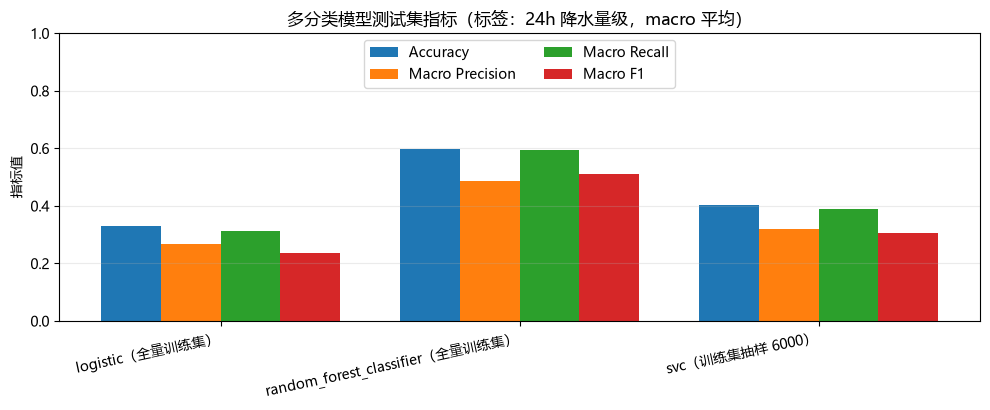

In [10]:
metrics = ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]
x = np.arange(len(grade_results))
width = 0.8 / len(metrics)

fig, ax = plt.subplots(figsize=(10, 4.2))
for i, name in enumerate(metrics):
    ax.bar(
        x + (i - (len(metrics) - 1) / 2) * width,
        grade_results[name], width=width, label=name,
    )
ax.set_xticks(x)
ax.set_xticklabels(grade_results["模型"], rotation=12, ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("指标值")
ax.set_title("多分类模型测试集指标（标签：24h 降水量级，macro 平均）")
ax.legend(ncol=2, loc="upper center")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

**4.2 结果解读**

二分类（未来 1 小时是否降水，正类约 9.8%）：

- `class_weight='balanced'` 下三种模型的少数类 Recall 为 0.63~0.71、Precision 为 0.34~0.44；随机森林 F1 最高（≈ 0.54），逻辑回归 F1 ≈ 0.45，RBF-SVC（6000 条训练样本）F1 ≈ 0.47。
- Accuracy 为 0.84~0.88，主要来自多数类（无降水），不能单独作为评价指标；本任务“全部预测为无降水”的基线 F1 = 0。
- 随机森林训练约 1.7~2.9 s、预测 1.1 万行约 0.08~0.10 s；逻辑回归训练约 0.2~0.4 s、预测约 0.02~0.12 s；RBF-SVC 预测约 4~7 s，明显最慢。

多分类（24h 降水量级，5 级）：

- 逻辑回归 Accuracy ≈ 0.33、macro-F1 ≈ 0.24，说明线性边界难以区分等级；随机森林 Accuracy ≈ 0.60、macro-F1 ≈ 0.51，优势明显。
- 随机森林对“无降水”和“暴雨”的召回最高（约 0.74 / 0.75），对“小雨”“中雨”较低（约 0.42 / 0.51），主要混淆发生在相邻等级之间。
- RBF-SVC（6000 条训练样本）macro-F1 ≈ 0.31，受样本量与一对一多分类策略影响，预测约 8~14 s，不适合本数据规模。
- 多分类 Accuracy 会被占比约 47% 的“无降水”主导，需同时看 macro-F1 与混淆矩阵。

> 说明：二分类采用“下一小时”标签以避免同一时刻的信息泄漏；但随机划分会让同一站点的相邻时刻分别落入训练/测试集，指标仍偏乐观，正式评估应按时间切分。多分类的降水列只用于构造标签，特征未使用降水列。

## 五、关键参数对性能的影响

### 5.1 PCA 主成分数：解释方差 ≠ 预测能力

左图给出原始特征与标准化后特征的累计解释方差；右图在若干取值（1, 2, 3, 4, 6, 8, 10, 11）上扫描 `n_components`，用 `LinearRegression` 评估测试集 `R²`，并对比“不使用 PCA”的基线。

,k,累计解释方差(原始),累计解释方差(标准化),R²(原始+PCA),R²(标准化+PCA)
0,1,0.7744,0.2922,0.0098,0.0123
1,2,0.9663,0.4775,0.0098,0.0578
2,3,0.9871,0.6276,0.0144,0.0797
3,4,0.9927,0.7274,0.1269,0.1025
4,6,0.9982,0.8783,0.1405,0.1725
5,8,0.9995,0.9549,0.1689,0.1725
6,10,1.0000,0.9878,0.1777,0.1744
7,11,1.0000,1.0000,0.1816,0.1816


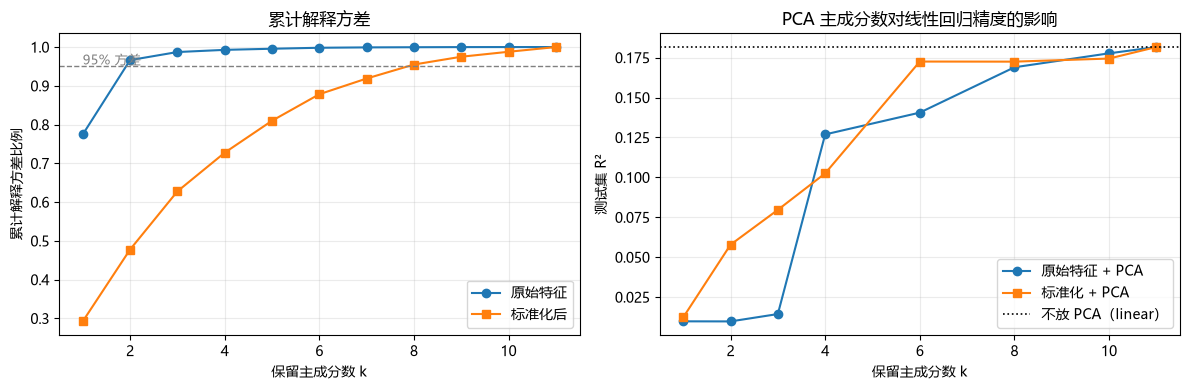

In [11]:
pca_raw = PCA(random_state=42).fit(X_train)
pca_scaled = PCA(random_state=42).fit(StandardScaler().fit_transform(X_train))
cum_raw = np.cumsum(pca_raw.explained_variance_ratio_)
cum_scaled = np.cumsum(pca_scaled.explained_variance_ratio_)

ks = [1, 2, 3, 4, 6, 8, 10, X_train.shape[1]]
r2_raw, r2_scaled = [], []
for k in ks:
    est = Pipeline(
        [("pca", PCA(n_components=k, random_state=42)), ("model", LinearRegression())]
    ).fit(X_train, y_train)
    r2_raw.append(r2_score(y_test, est.predict(X_test)))

    est = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=k, random_state=42)),
        ("model", LinearRegression()),
    ]).fit(X_train, y_train)
    r2_scaled.append(r2_score(y_test, est.predict(X_test)))

baseline_r2 = r2_score(y_test, predictions["linear"])
pca_df = pd.DataFrame({
    "k": ks,
    "累计解释方差(原始)": cum_raw[np.array(ks) - 1],
    "累计解释方差(标准化)": cum_scaled[np.array(ks) - 1],
    "R²(原始+PCA)": r2_raw,
    "R²(标准化+PCA)": r2_scaled,
})
display(pca_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, len(cum_raw) + 1), cum_raw, "o-", label="原始特征")
axes[0].plot(range(1, len(cum_scaled) + 1), cum_scaled, "s-", label="标准化后")
axes[0].axhline(0.95, color="gray", ls="--", lw=1)
axes[0].text(1, 0.955, "95% 方差", fontsize=9, color="gray")
axes[0].set_xlabel("保留主成分数 k")
axes[0].set_ylabel("累计解释方差比例")
axes[0].set_title("累计解释方差")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(ks, r2_raw, "o-", label="原始特征 + PCA")
axes[1].plot(ks, r2_scaled, "s-", label="标准化 + PCA")
axes[1].axhline(baseline_r2, color="k", ls=":", lw=1.2, label="不放 PCA（linear）")
axes[1].set_xlabel("保留主成分数 k")
axes[1].set_ylabel("测试集 R²")
axes[1].set_title("PCA 主成分数对线性回归精度的影响")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

**结果解读**

- 原始特征只需 2 个主成分即可解释约 96.6% 的总方差，但此时线性回归的 `R²` 仅约 0.01；4 个主成分解释约 99.3% 方差，`R²` 也只有约 0.13。
- 直到保留全部 11 个主成分，`R²` 才回到不放 PCA 的约 0.18。说明对本任务而言，与 `TEM` 相关的信号并不在方差最大的方向上。
- 标准化后各主成分方差更均衡，4 个主成分的 `R²` 约 0.10，同样需要接近全部主成分才能恢复基线。
- 结论：PCA 是**降维/压缩/可视化**工具，不是默认的精度提升手段。使用前应与“不放 PCA”的基线对比；若使用，先标准化，并保留足够多的主成分。

### 5.2 随机森林：树数与深度

固定 `max_depth=10`，比较 `n_estimators ∈ {10, 30, 100}`；再固定 `n_estimators=50`，比较 `max_depth ∈ {3, 5, 10, None}`。其余设置相同（`n_jobs=-1, random_state=42`）。

树数实验（max_depth=10）：


,n_estimators,训练耗时(s),预测耗时(ms),模型体积(MB),RMSE,R²
0,10,0.5341,16.6864,1.1589,2.4405,0.7072
1,30,1.4229,28.8358,3.4599,2.4125,0.7138
2,100,4.4155,61.9491,11.5268,2.4144,0.7134


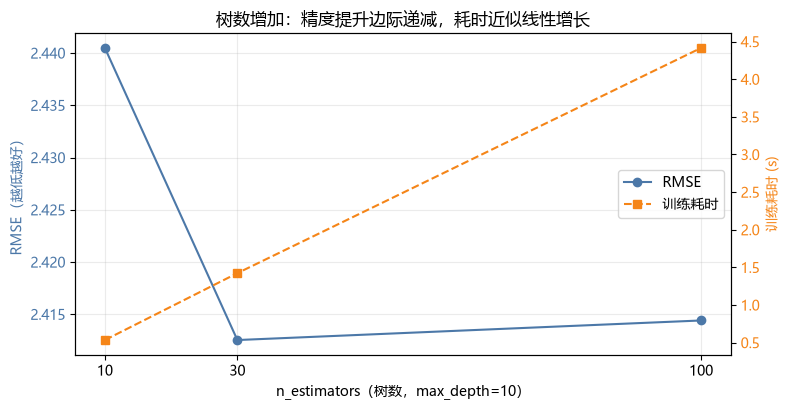

In [12]:
def rf_sweep(param_name, values, base_kwargs):
    rows = []
    for value in values:
        estimator = make_estimator(
            "random_forest", {**base_kwargs, param_name: value}
        )
        t0 = time.perf_counter()
        estimator.fit(X_train, y_train)
        fit_s = time.perf_counter() - t0

        t0 = time.perf_counter()
        y_pred = estimator.predict(X_test)
        predict_ms = (time.perf_counter() - t0) * 1000

        rows.append({
            param_name: "None" if value is None else value,
            "训练耗时(s)": fit_s,
            "预测耗时(ms)": predict_ms,
            "模型体积(MB)": model_size_mb(estimator),
            "RMSE": float(np.sqrt(mean_squared_error(y_test, y_pred))),
            "R²": float(r2_score(y_test, y_pred)),
        })
    return pd.DataFrame(rows)


n_df = rf_sweep(
    "n_estimators", [10, 30, 100],
    {"max_depth": 10, "n_jobs": -1, "random_state": 42},
)
print("树数实验（max_depth=10）：")
display(n_df.round(4))

fig, ax1 = plt.subplots(figsize=(8, 4.2))
ax1.plot(n_df["n_estimators"], n_df["RMSE"], "o-", color="#4C78A8", label="RMSE")
ax1.set_xlabel("n_estimators（树数，max_depth=10）")
ax1.set_ylabel("RMSE（越低越好）", color="#4C78A8")
ax1.tick_params(axis="y", labelcolor="#4C78A8")
ax1.set_xticks(n_df["n_estimators"])

ax2 = ax1.twinx()
ax2.plot(
    n_df["n_estimators"], n_df["训练耗时(s)"], "s--", color="#F58518", label="训练耗时"
)
ax2.set_ylabel("训练耗时 (s)", color="#F58518")
ax2.tick_params(axis="y", labelcolor="#F58518")

lines = ax1.get_lines() + ax2.get_lines()
ax1.legend(lines, [line.get_label() for line in lines], loc="center right")
ax1.grid(alpha=0.25)
ax1.set_title("树数增加：精度提升边际递减，耗时近似线性增长")
plt.tight_layout()
plt.show()

深度实验（n_estimators=50）：


,max_depth,训练耗时(s),预测耗时(ms),模型体积(MB),RMSE,R²
0,3,0.8681,27.8030,0.0676,3.5567,0.3780
1,5,1.1870,40.7840,0.2324,3.1302,0.5183
2,10,2.2670,39.3259,5.7699,2.4144,0.7134
3,None,4.2251,82.4231,182.4198,1.9762,0.8080


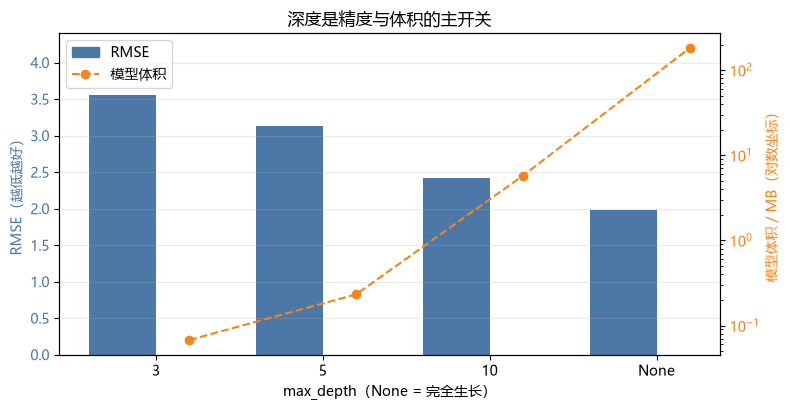

In [13]:
d_df = rf_sweep(
    "max_depth", [3, 5, 10, None],
    {"n_estimators": 50, "n_jobs": -1, "random_state": 42},
)
print("深度实验（n_estimators=50）：")
display(d_df.round(4))

x = np.arange(len(d_df))
depth_labels = d_df["max_depth"].astype(str)
fig, ax1 = plt.subplots(figsize=(8, 4.2))
ax1.bar(x - 0.2, d_df["RMSE"], width=0.4, color="#4C78A8", label="RMSE")
ax1.set_xticks(x)
ax1.set_xticklabels(depth_labels)
ax1.set_xlabel("max_depth（None = 完全生长）")
ax1.set_ylabel("RMSE（越低越好）", color="#4C78A8")
ax1.tick_params(axis="y", labelcolor="#4C78A8")

ax2 = ax1.twinx()
ax2.plot(x + 0.2, d_df["模型体积(MB)"], "o--", color="#F58518", label="模型体积")
ax2.set_yscale("log")
ax2.set_ylabel("模型体积 / MB（对数坐标）", color="#F58518")
ax2.tick_params(axis="y", labelcolor="#F58518")

lines = [plt.Rectangle((0, 0), 1, 1, color="#4C78A8")] + ax2.get_lines()
ax1.set_ylim(0, 4.4)
ax1.legend(lines, ["RMSE", "模型体积"], loc="upper left")
ax1.grid(axis="y", alpha=0.25)
ax1.set_title("深度是精度与体积的主开关")
plt.tight_layout()
plt.show()

**结果解读**

- 树数：`max_depth=10` 时，10 → 30 棵树有明显收益（R² 约 0.707 → 0.714），30 → 100 基本饱和（约 0.713）；训练时间近似线性增长（约 0.4 → 1.2 → 3.6 s），模型体积也近似线性（约 1.2 → 3.5 → 11.5 MB）。
- 深度：`depth=3/5` 明显欠拟合（R² 约 0.38 / 0.52）；`depth=10` 已接近实用精度（约 0.71）；`None`（完全生长）精度最高（约 0.81），但 50 棵树就有约 180 MB，100 棵树达数百 MB，预测也更慢。
- 实践建议：优先用 `max_depth`、`min_samples_leaf` 控制模型复杂度，再增加 `n_estimators`；用验证集或 `oob_score=True` 选择参数，避免只看训练集。
- 本数据上 RF 相对线性模型的巨大提升（R² 约 0.18 → 0.81）说明主要信号包含非线性/交互，单靠线性模型无法表达。

## 六、复杂度与选型建议

| 算法 | 训练复杂度（近似） | 预测复杂度 | 模型/内存 | 是否需标准化 | 适合场景 |
|---|---|---|---|---|---|
| `LinearRegression` | `O(np² + p³)` | `O(p)` | `O(p)` | 否（无正则） | 基线、可解释、线性关系 |
| `BayesianRidge` | `O(iter · (np² + p³))` | `O(p)` | `O(p)` + 后验 | 否（尺度自适应），但建议 | 中等样本、需要不确定性/自动正则 |
| `RandomForestRegressor` | `O(T · n log n · max_features)` | `O(T · depth)` | `O(T · 节点数)` | 否 | 非线性、交互、无需精细特征处理 |
| `LogisticRegression` | `O(iter · np²)`（依 solver） | `O(p)` | `O(p)` | 建议 | 二分类/多分类基线、可解释、概率输出 |
| `RandomForestClassifier` | `O(T · n log n · max_features)` | `O(T · depth)` | `O(T · 节点数)` | 否 | 非线性分类、交互、类别不平衡 |
| `SVC` | 约 `O(n²)`~`O(n³)` | `O(n_SV · p)` | `O(n_SV · p)` | 强烈建议 | 中小样本、高维、核方法 |
| `PCA` | 约 `O(np · min(n,p))`，依 solver | `O(pk)` | `O(pk)` | 强烈建议 | 降维、去共线、可视化、压缩 |
| `StandardScaler` | `O(np)` | `O(np)` | `O(p)` | — | 正则/距离/梯度类模型、PCA 前置 |

> 复杂度为量级估计，实际实现（LAPACK、随机 SVD、CART 优化）与常数因子会有差异。

**选型建议**

1. 先跑 `linear` 基线；若残差仍有明显结构，再考虑随机森林。
2. 需要预测区间/概率输出时，用 `BayesianRidge` 的 `predict(X, return_std=True)`。
3. 随机森林用 `max_depth` / `min_samples_leaf` / `n_estimators` 平衡精度—体积—速度；默认不限深度可能产生数百 MB 模型。
4. PCA 不是精度工具；使用前对比“不放 PCA”的基线，并先标准化。
5. `StandardScaler` 对无正则线性/贝叶斯点预测基本无影响，但对正则化模型、距离/核方法、神经网络与 PCA 通常是必需的。
6. `n_jobs=-1` 可加速训练但会增加内存；大数据下按核数与内存折中。
7. 分类任务先跑 `logistic` 基线（配合标准化），非线性明显时上 `random_forest_classifier`；类别不平衡用 `class_weight='balanced'`，评估重点看少数类 Precision/Recall/F1 而非 Accuracy。
8. RBF 核 `SVC` 训练复杂度接近 `O(n²)`，样本量大时耗时与内存快速增长；必要时抽样、改用线性核或换用随机森林。
9. 多分类（如降水量级）：三种分类器均原生支持；优先随机森林，评估用 macro 平均的 Precision/Recall/F1 与混淆矩阵，避免被多数类的 Accuracy 掩盖。

## 七、在本框架中调用

- 插件类 `SklearnCal` 通过 `__init__` 给出模型、模型参数与特征工程，通过 `process` 执行主功能；
- **回归 / 分类自动判定**：框架根据所选估计器类型（`sklearn.base.is_classifier`）决定任务类型，无需额外参数；
- `process(..., mode="train")` 执行训练：须指定 `target_col`，返回已拟合估计器（有效样本 <2 时返回 `None`；拟合失败时原样抛出 sklearn 异常）；
- `process(..., mode="predict")` 执行推理：使用训练缓存或 `__init__(estimator=...)` 传入的模型，输出维度列 + 预测列（回归为连续值，分类为类别标签，二分类/多分类均输出标签）；
- 模型参数放 `model_kwargs`，特征工程参数放 `feat_kwargs`；
- `model` / `feat_model` 可传算法名字符串、sklearn 类或已构造实例；传实例时对应的 kwargs 必须为空；
- 需要“标准化 + PCA”时，把 `Pipeline` 实例传给 `feat_model`。

下面用 RF（50 棵、深度 5）+ StandardScaler 演示同一插件的训练与推理；第 4.2 节演示二分类（未来 1 小时是否降水）与多分类（24 小时降水量级）任务。

In [14]:
cal = SklearnCal(
    model="random_forest",
    model_kwargs={
        "n_estimators": 50, "max_depth": 5, "random_state": 42, "n_jobs": -1
    },
    feat_model="standard_scaler",
    feat_kwargs={"with_mean": True, "with_std": True},
)
estimator = cal.process(
    df, feature_cols=FEATURE_COLS, target_col=TARGET_COL, mode="train"
)
print(cal)
print("返回类型:", type(estimator).__name__)
print(estimator)

predict_df = pd.read_csv(
    REPO_ROOT / "resource" / "data" / "predict_data.txt", parse_dates=["time"]
)
for col in ["WIN_D_Avg_10mi", "WIN_D_INST_Max"]:
    predict_df.loc[predict_df[col] == 999017, col] = np.nan

t0 = time.perf_counter()
prediction_df = cal.process(
    predict_df, feature_cols=FEATURE_COLS, mode="predict", data_name="TEM_pred"
)
infer_ms = (time.perf_counter() - t0) * 1000
print(f"\n预测 {len(prediction_df):,} 行，耗时 {infer_ms:.1f} ms")
display(prediction_df.head())


<SklearnCal: model='random_forest', model_kwargs={'n_estimators': 50, 'max_depth': 5, 'random_state': 42, 'n_jobs': -1}, feat_model='standard_scaler', feat_kwargs={'with_mean': True, 'with_std': True}, estimator=Pipeline>
返回类型: Pipeline
Pipeline(steps=[('feature_engineering', StandardScaler()),
                ('model',
                 RandomForestRegressor(max_depth=5, n_estimators=50, n_jobs=-1,
                                       random_state=42))])

预测 2,344 行，耗时 42.1 ms


,level,time,dtime,id,lon,lat,TEM_pred
0,NaN,2023-08-01 16:00:00,0,54809,115.2903,36.5489,26.676533
1,NaN,2023-08-01 16:00:00,0,54803,116.0211,36.9775,28.673048
2,NaN,2023-08-01 16:00:00,0,57089,113.9258,34.0733,26.889339
3,NaN,2023-08-01 16:00:00,0,59264,111.5081,23.3972,25.788855
4,NaN,2023-08-01 16:00:00,0,57082,113.1056,34.4892,25.644175


## 八、结论

1. **调度方式**：统一由 `SklearnCal` 完成——`__init__` 配置 `model` / `model_kwargs` / `feat_model` / `feat_kwargs`，`process` 以 `mode="train"` / `mode="predict"` 区分训练与推理；**回归/分类由估计器类型自动判定**，无需 `task` 参数；分类支持二分类与多分类，预测列输出类别标签。
2. **精度（回归）**：本数据上随机森林 `R² ≈ 0.81`，显著优于线性/贝叶斯（`≈ 0.18`）；后者速度极快、模型极小，适合作为基线。
3. **速度与体积**：线性/贝叶斯训练约 10 ms、模型 <2 KB；默认 RF 训练约 7 s、模型约 365 MB、预测约 0.25 s / 1.1 万行。RF 的精度收益伴随明显的计算与存储代价。
4. **特征工程**：StandardScaler 对无正则线性/贝叶斯点预测基本无影响；PCA 在本任务上降低精度——**解释方差大 ≠ 预测有用**，PCA 使用前应与不降维基线对比并先标准化。
5. **调参优先级（RF）**：先用 `max_depth` / `min_samples_leaf` 控制复杂度，再增加 `n_estimators`；树数收益会饱和，深度对体积影响最大。
6. **不确定性**：需要预测区间时，用 `BayesianRidge.predict(X, return_std=True)`。
7. **分类接口**：`logistic` / `random_forest_classifier` / `svc` 与回归共用同一接口；降水累计列既可作为特征（预测未来降水），也可用于构造多级分类标签（如 `PRE_24h` 量级）。
8. **二分类（未来 1 小时是否降水）**：正类约 9.8%，`class_weight='balanced'` 下 Recall 0.63~0.71、Precision 0.34~0.44，F1 0.45~0.54（随机森林最好）；Accuracy 0.84~0.88 主要来自多数类，**不平衡场景应看 Precision/Recall/F1**。
9. **多分类（24h 降水量级）**：随机森林 Accuracy ≈ 0.60、macro-F1 ≈ 0.51，明显优于逻辑回归（macro-F1 ≈ 0.24）与抽样 SVC（≈ 0.31）；应使用 macro 平均与混淆矩阵评估，避免被“无降水”多数类掩盖。
10. **分类速度**：逻辑回归训练/预测极快；随机森林（100 棵、深度 10）训练约 2~3 s、预测 1.1 万行约 0.08~0.26 s；RBF-SVC 仅用 6000 条训练样本，二分类预测约 4~7 s、多分类约 8~14 s，大样本场景需抽样或换模型。
11. **评估提醒**：本 Notebook 使用随机划分、单次计时，指标偏乐观且计时受硬件影响；降水临近预报存在时间自相关，正式评估应按时间切分并多次重复。

**复现**：安装 `env/requirements.txt` 依赖后，运行 `jupyter lab nbs/算法参数和性能介绍.ipynb`。

**完整参数表**：`docs/算法参数清单.md`；官方文档：https://scikit-learn.org/stable/modules/generated/ 下按类查询。